# 03 — Spatial structure

Fitting the model.

LunaRec decides which patch to image next. To do that it has to hold a belief
about patches it has *not* imaged — otherwise there is nothing to be uncertain
about and nothing for an acquisition to resolve. That belief is a Gaussian
process over each attribute, and the GP is defined entirely by its covariance:
how strongly two patches are expected to agree as a function of how far apart
they are.

So the covariance is not a tuning detail. It is the model. Three numbers
describe it:

| | meaning | consequence if wrong |
|---|---|---|
| **range** | separation beyond which patches are uncorrelated | sets how far one observation informs its neighbours |
| **sill** | total variance of the field | scales everything |
| **nugget** | variance left at zero separation | how much is unlearnable from neighbours |

The criterion propagates information through exactly this covariance, so it is
the policy most exposed to getting it wrong.

### Why this notebook exists

An earlier revision of `evaluate.py` hardcoded a range of 1100 m and a nugget
of 0.10, carried from a single early fit. Measured against the scenes, those
were wrong by roughly **3× in range and 5× in nugget**. Every result produced
under them came from a GP that believed observations stop informing neighbours
at about a kilometre when they actually carry to three, and that a tenth of the
signal was noise when nearly half is.

This notebook replaces those assumptions with measurements, per scene and per
attribute, by two independent methods:

1. **Variogram fitting** — bin the semivariance by separation and fit the
   spherical model by weighted least squares. Interpretable: you can look at
   the binned points and see whether the model describes them.
2. **Marginal likelihood** — optimise the GP hyperparameters directly by
   maximising the log marginal likelihood of the observed data. More
   principled, and it is a training procedure in the ordinary sense: a loss, an
   optimiser, learned parameters, a convergence curve.

Keeping both is deliberate. Two independent estimates agreeing is a stronger
result than either alone, and disagreement would be informative in itself.

### What to expect

The hazard nugget comes out near **0.45**. Read on its own that looks like
noise, which would be bad news. Read against notebook 02's repeatability — 78%
to 91% of the label's variance is reproducible ground — it says something more
useful: roughly half the variance is **real structure finer than the 200 m
patch grid**, not measurement error.

That is the quantitative reason hazard cannot be extrapolated from neighbouring
patches, and therefore the reason verification imaging is necessary at all. It
is the strongest single argument for the project's premise, and it is measured
rather than assumed.

### A note on method

This notebook imports `empirical_variogram`, `fit` and `spherical_model` from
`src/fit_variogram.py` rather than reimplementing them. What is validated here
is the code that actually runs in `evaluate.py`; a notebook copy would be free
to drift from the pipeline, and the figures would then describe something the
pipeline does not do.

**Cell 1** - setup

In [3]:
import importlib, fit_variogram2
importlib.reload(fit_variogram2)
from fit_variogram import empirical_variogram, fit as fit_spherical, spherical_model

# Confirm the new weighting is live before re-running anything else.
import inspect
src = inspect.getsource(fit_variogram2.fit)
print("Cressie weighting active:", "np.maximum(gamma, 1e-6) / np.sqrt(counts)" in src)
print("data-driven range bound:", "hi_range = float(centres.max())" in src)

Cressie weighting active: True
data-driven range bound: True


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from lunarec_style import *                      # noqa: F403
# Import the PIPELINE implementation rather than reimplementing it here, so
# this notebook validates the code that actually runs in evaluate.py. A
# notebook copy would be free to drift from it, and then the figures would
# describe something the pipeline does not do.
from fit_variogram2 import empirical_variogram, fit as fit_spherical, spherical_model

PATCHES = ROOT / "data" / "patches" / "current"
out = ROOT / "results" / "figures"
out.mkdir(parents=True, exist_ok=True)

SCENES = {
    "0858":  ("B", "patches_0858_rt.csv"),
    "1647a": ("B", "patches_1647a_rt.csv"),
    "C1":    ("C", "patches_C1.csv"),
    "C2":    ("C", "patches_C2.csv"),
}
# (column, label, stakeholder) -- the three attributes the recommender ranks on.
ATTRS = [
    ("shadow_local", "hazard",       "safety"),
    ("dn_mean",      "illumination", "operations"),
    ("dn_std",       "texture",      "science"),
]
SUBSAMPLE = 1400     # pair count is O(n^2); 1400 gives ~1M pairs per fit

scenes = {lab: pd.read_csv(PATCHES / f).dropna(
              subset=[c for c, _, _ in ATTRS] + ["patch_x", "patch_y"])
          for lab, (_, f) in SCENES.items()}

print(f"{len(scenes)} scenes loaded")
for lab, d in scenes.items():
    print(f"  {lab:<6} {len(d):>5} patches")
print(f"\nsubsample for variograms: {SUBSAMPLE} "
      f"(~{SUBSAMPLE*(SUBSAMPLE-1)//2:,} pairs per fit)")
print(f"imported from src/fit_variogram2.py: "
      f"{', '.join(['empirical_variogram', 'fit', 'spherical_model'])}")

4 scenes loaded
  0858    2010 patches
  1647a   2008 patches
  C1      1875 patches
  C2      1930 patches

subsample for variograms: 1400 (~979,300 pairs per fit)
imported from src/fit_variogram2.py: empirical_variogram, fit, spherical_model


**Cell 2** — empirical variograms and the spherical fit, all twelve:

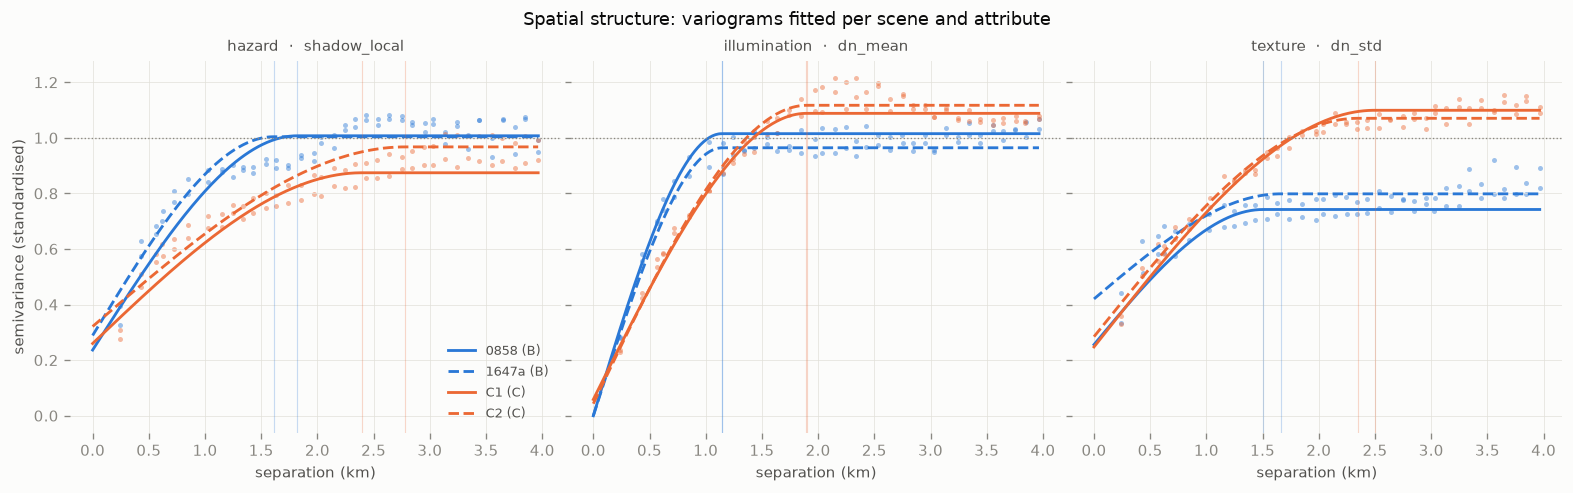

            fit_r2                      nugget                        range_m                       
attribute   hazard illumination texture hazard illumination texture    hazard illumination   texture
block scene                                                                                         
B     0858   0.852        0.967   0.846  0.235        0.000   0.345  1818.757     1143.466  1503.520
      1647a  0.835        0.946   0.742  0.288        0.000   0.527  1610.797     1148.057  1660.092
C     C1     0.908        0.972   0.984  0.297        0.054   0.225  2394.032     1895.547  2495.827
      C2     0.930        0.963   0.972  0.332        0.039   0.266  2781.580     1901.735  2346.922


In [2]:
# Twelve fits: four scenes x three attributes.
#
# Each attribute is standardised first, so the sill lands near 1 and the
# nugget reads directly as the FRACTION of variance that is uncorrelated at
# the patch grid's own spacing. That is the number evaluate.py consumes.
#
# Weighted least squares on the binned semivariance, weights = pair counts, so
# the well-populated short lags -- which determine the nugget and the range --
# are not outvoted by the many noisy long-lag bins.
BLOCK_COLOR = {"B": "#2a78d6", "C": "#eb6834"}
SCENE_STYLE = {"0858": "-", "1647a": "--", "C1": "-", "C2": "--"}

vg = {}      # (scene, attr) -> (centres, gamma, counts, nugget, sill, range, r2)
rows = []
for lab, d in scenes.items():
    block = SCENES[lab][0]
    sub = d.sample(min(SUBSAMPLE, len(d)), random_state=0)
    xy = sub[["patch_x", "patch_y"]].values
    for col, name, holder in ATTRS:
        raw = sub[col].values.astype(float)
        z = (raw - raw.mean()) / raw.std()
        c, g, k = empirical_variogram(xy, z)
        (nug, sill, rng_), r2 = fit_spherical(c, g, k)
        vg[(lab, col)] = (c, g, k, nug, sill, rng_, r2)
        rows.append({"scene": lab, "block": block, "attribute": name,
                     "range_m": rng_, "nugget": nug / sill, "sill": sill,
                     "fit_r2": r2})

fits = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.0), sharey=True,
                         constrained_layout=True)
for ax, (col, name, holder) in zip(axes, ATTRS):
    for lab in scenes:
        block = SCENES[lab][0]
        c, g, k, nug, sill, rng_, r2 = vg[(lab, col)]
        ax.scatter(c / 1000, g, s=9, color=BLOCK_COLOR[block], alpha=0.45,
                   linewidths=0)
        hh = np.linspace(0, c.max(), 300)
        ax.plot(hh / 1000, spherical_model(hh, nug, sill, rng_),
                color=BLOCK_COLOR[block], linestyle=SCENE_STYLE[lab],
                linewidth=1.7, label=f"{lab} ({block})")
        # The fitted range, marked where the model reaches its sill.
        ax.axvline(rng_ / 1000, color=BLOCK_COLOR[block], linewidth=0.7,
                   alpha=0.25)
    ax.axhline(1.0, color=MUTED, linewidth=0.8, linestyle=":")
    ax.set_title(f"{name}  ·  {col}", color=INK2, fontsize=9)
    ax.set_xlabel("separation (km)")
    bare(ax)
axes[0].set_ylabel("semivariance (standardised)")
axes[0].legend(frameon=False, fontsize=8, labelcolor=INK2, loc="lower right")
fig.suptitle("Spatial structure: variograms fitted per scene and attribute",
             color=INK, fontsize=11)
fig.savefig(out / "03_variograms.png", bbox_inches="tight")
plt.show()

print(fits.pivot_table(index=["block", "scene"], columns="attribute",
                       values=["range_m", "nugget", "fit_r2"]).round(3)
      .to_string())

**Cell 3** — is the 4 km window long enough?

In [20]:
# The sill should land at 1.0: the attributes are standardised, so total
# variance is 1 by construction. Several fits saturate well below that, which
# means correlated structure continues past the 4 km window fit_variogram2.py
# examines.
#
# That matters beyond tidiness. The nugget is reported as nugget/sill, so a
# sill fitted at 0.75 inflates the reported nugget fraction by a third against
# the true share of variance. evaluate.py consumes that ratio directly.
#
# The scenes are ~29 km across the diagonal, so lags to 8 km are well sampled.
LAGS = [4000.0, 6000.0, 8000.0]

rows = []
for lab, d in scenes.items():
    sub = d.sample(min(SUBSAMPLE, len(d)), random_state=0)
    xy = sub[["patch_x", "patch_y"]].values
    for col, name, _ in ATTRS:
        raw = sub[col].values.astype(float)
        z = (raw - raw.mean()) / raw.std()
        for L in LAGS:
            c, g, k = empirical_variogram(xy, z, max_lag=L)
            (nug, sill, rng_), r2 = fit_spherical(c, g, k)
            rows.append({"scene": lab, "attribute": name, "max_lag_km": L / 1000,
                         "sill": sill, "range_m": rng_,
                         "nugget/sill": nug / sill, "nugget/total": nug,
                         "fit_r2": r2})
lagtest = pd.DataFrame(rows)

print("sill by fit window (should be ~1.0 on standardised data)")
print(lagtest.pivot_table(index=["scene", "attribute"], columns="max_lag_km",
                          values="sill").round(3).to_string())
print("\nfitted range (m) by fit window")
print(lagtest.pivot_table(index=["scene", "attribute"], columns="max_lag_km",
                          values="range_m").round(0).to_string())
print("\nnugget as a fraction of TOTAL variance (not of the fitted sill)")
print(lagtest.pivot_table(index=["scene", "attribute"], columns="max_lag_km",
                          values="nugget/total").round(3).to_string())

worst = lagtest[lagtest.max_lag_km == 4.0].nsmallest(3, "sill")
print(f"\nfurthest from a unit sill at 4 km: "
      f"{', '.join(f'{r.scene}/{r.attribute} {r.sill:.2f}' for r in worst.itertuples())}")

sill by fit window (should be ~1.0 on standardised data)
max_lag_km            4.0    6.0    8.0
scene attribute                        
0858  hazard        1.037  1.028  1.019
      illumination  1.016  1.052  1.060
      texture       0.750  0.902  1.002
1647a hazard        1.048  1.060  1.033
      illumination  0.968  0.967  0.933
      texture       0.815  0.862  0.872
C1    hazard        0.905  1.015  1.148
      illumination  1.095  1.121  1.169
      texture       1.107  1.146  1.242
C2    hazard        0.998  1.033  1.093
      illumination  1.124  1.130  1.172
      texture       1.077  1.131  1.334

fitted range (m) by fit window
max_lag_km             4.0     6.0     8.0
scene attribute                           
0858  hazard        2535.0  2462.0  2413.0
      illumination  1117.0  1211.0  1250.0
      texture       1850.0  5940.0  7909.0
1647a hazard        2750.0  2875.0  2615.0
      illumination  1221.0  1226.0  1072.0
      texture       2523.0  4527.0  4814.0
C1    h

**Is the along-strip structure instrumental?**

In [11]:
# Terrain genuinely varies along a strip, so a gradient in the attribute alone
# proves nothing. The discriminator is the DIFFERENCE between two scenes
# covering the same ground: terrain cancels, and whatever gradient survives
# belongs to the acquisition rather than the Moon.
#
# A pushbroom reads a line at once across-track and accumulates down-track, so
# radiometric drift, gain change or slow illumination change during the pass
# should appear as an along-strip gradient in the difference -- and not an
# across-strip one, which is the control.
GRID_M = 200.0

def project(xy, axis_deg):
    """Along- and across-strip coordinates, metres from the centroid."""
    a = np.radians(axis_deg)
    c = xy - xy.mean(0)
    along = c[:, 0] * np.cos(a) + c[:, 1] * np.sin(a)
    across = -c[:, 0] * np.sin(a) + c[:, 1] * np.cos(a)
    return along, across

def lin_r2(x, y):
    """R^2 of a straight-line fit, plus the slope per km."""
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    if len(x) < 50 or x.std() == 0 or y.std() == 0:
        return np.nan, np.nan
    b, a = np.polyfit(x, y, 1)
    pred = a + b * x
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return float(r2), float(b * 1000.0)        # slope per km

# --- context: how much does each attribute itself trend? -----------------
rows = []
for lab, d in scenes.items():
    xy = d[["patch_x", "patch_y"]].values
    s, t = project(xy, strip_axis_deg(xy))
    for col, name, _ in ATTRS:
        v = d[col].values.astype(float)
        r2s, _ = lin_r2(s, v)
        r2t, _ = lin_r2(t, v)
        rows.append({"scene": lab, "attribute": name,
                     "R2 along": r2s, "R2 across": r2t})
print("context -- gradient in the attribute itself (terrain + acquisition)")
print(pd.DataFrame(rows).pivot_table(index=["scene", "attribute"],
      values=["R2 along", "R2 across"]).round(3).to_string())

# --- the decisive test: gradient in the DIFFERENCE ------------------------
PAIRS = [("0858", "1647a"), ("C1", "C2")]
rows = []
for a, b in PAIRS:
    da, db = scenes[a].copy(), scenes[b].copy()
    for d in (da, db):
        d["gx"] = np.floor(d.patch_x / GRID_M).astype(np.int64)
        d["gy"] = np.floor(d.patch_y / GRID_M).astype(np.int64)
    m = da.merge(db, on=["gx", "gy"], suffixes=("_a", "_b"))
    xy = m[["patch_x_a", "patch_y_a"]].values
    axis = strip_axis_deg(xy)
    s, t = project(xy, axis)
    for col, name, _ in ATTRS:
        # Standardise each scene before differencing, so a pure scale change
        # between passes does not masquerade as a gradient.
        za = (m[f"{col}_a"] - m[f"{col}_a"].mean()) / m[f"{col}_a"].std()
        zb = (m[f"{col}_b"] - m[f"{col}_b"].mean()) / m[f"{col}_b"].std()
        diff = (za - zb).values
        r2s, slope_s = lin_r2(s, diff)
        r2t, slope_t = lin_r2(t, diff)
        rows.append({"pair": f"{a}-{b}", "attribute": name, "shared": len(m),
                     "R2 along": r2s, "slope along /km": slope_s,
                     "R2 across": r2t, "slope across /km": slope_t})
diffs = pd.DataFrame(rows)
print("\nDECISIVE -- gradient in the scene-to-scene DIFFERENCE")
print("(terrain cancels; what remains is the acquisition)\n")
print(diffs.set_index(["pair", "attribute"]).round(4).to_string())

print(f"\nmean R2 along  {diffs['R2 along'].mean():.4f}"
      f"     mean R2 across {diffs['R2 across'].mean():.4f}")

context -- gradient in the attribute itself (terrain + acquisition)
                    R2 across  R2 along
scene attribute                        
0858  hazard            0.016     0.014
      illumination      0.001     0.001
      texture           0.000     0.144
1647a hazard            0.000     0.034
      illumination      0.001     0.030
      texture           0.000     0.050
C1    hazard            0.001     0.024
      illumination      0.010     0.009
      texture           0.016     0.000
C2    hazard            0.007     0.010
      illumination      0.000     0.006
      texture           0.007     0.002

DECISIVE -- gradient in the scene-to-scene DIFFERENCE
(terrain cancels; what remains is the acquisition)

                         shared  R2 along  slope along /km  R2 across  slope across /km
pair       attribute                                                                   
0858-1647a hazard          1587    0.0000          -0.0002     0.0038            0.0372
 

**Cell 4** — does detrending make the ranges identifiable?

In [9]:
# A range that grows with the fit window is not a range. It is the window.
# The usual cause is a spatial trend: a trended field's variogram rises without
# bound, so a bounded model fitted to it returns roughly the window size.
#
# Removing a quadratic trend in (x, y) before computing the variogram tests
# that directly. If the ranges stabilise afterwards, the fields are stationary
# once the trend is out and the pipeline's stationary fit is a documented
# approximation. If they still grow, something else is going on -- anisotropy
# is the next suspect, since these are long thin strips and a variogram pooled
# over all directions mixes along-track with cross-track structure.
def detrend_xy(v, xs, ys):
    sx = (xs - xs.mean()) / max(xs.std(), 1.0)
    sy = (ys - ys.mean()) / max(ys.std(), 1.0)
    A = np.column_stack([np.ones_like(sx), sx, sy, sx*sx, sx*sy, sy*sy])
    coef, *_ = np.linalg.lstsq(A, v, rcond=None)
    return v - A @ coef

rows = []
for lab, d in scenes.items():
    sub = d.sample(min(SUBSAMPLE, len(d)), random_state=0)
    xy = sub[["patch_x", "patch_y"]].values
    xs, ys = xy[:, 0], xy[:, 1]
    for col, name, _ in ATTRS:
        raw = sub[col].values.astype(float)
        for mode in ("raw", "detrended"):
            v = raw if mode == "raw" else detrend_xy(raw, xs, ys)
            z = (v - v.mean()) / v.std()
            for L in (4000.0, 8000.0):
                c, g, k = empirical_variogram(xy, z, max_lag=L)
                (nug, sill, rng_), r2 = fit_spherical(c, g, k)
                rows.append({"scene": lab, "attribute": name, "mode": mode,
                             "lag_km": L / 1000, "range_m": rng_,
                             "sill": sill, "nugget": nug})
dt = pd.DataFrame(rows)

print("fitted range (m): does it stop chasing the window once detrended?")
print(dt.pivot_table(index=["scene", "attribute"], columns=["mode", "lag_km"],
                     values="range_m").round(0).to_string())

# Range drift, as a ratio. ~1 means identified; >>1 means window-dependent.
drift = (dt.pivot_table(index=["scene", "attribute"], columns=["mode", "lag_km"],
                        values="range_m"))
ratio = pd.DataFrame({
    "raw 8km/4km":       drift[("raw", 8.0)] / drift[("raw", 4.0)],
    "detrended 8km/4km": drift[("detrended", 8.0)] / drift[("detrended", 4.0)],
})
print("\nrange drift ratio (1.0 = identified, >1.5 = window-dependent)")
print(ratio.round(2).to_string())
print(f"\nmean drift   raw {ratio['raw 8km/4km'].mean():.2f}"
      f"   detrended {ratio['detrended 8km/4km'].mean():.2f}")

fitted range (m): does it stop chasing the window once detrended?
mode               detrended             raw        
lag_km                   4.0     8.0     4.0     8.0
scene attribute                                     
0858  hazard          2566.0  2445.0  2535.0  2413.0
      illumination    1088.0  1140.0  1117.0  1250.0
      texture         1403.0  1572.0  1850.0  7909.0
1647a hazard          2749.0  2567.0  2750.0  2615.0
      illumination    1067.0   957.0  1221.0  1072.0
      texture          973.0   812.0  2523.0  4814.0
C1    hazard          2873.0  7703.0  3232.0  7896.0
      illumination    2042.0  2358.0  2029.0  2409.0
      texture         2772.0  4102.0  2648.0  4474.0
C2    hazard          3566.0  4599.0  3525.0  5161.0
      illumination    1992.0  2154.0  1984.0  2156.0
      texture         2554.0  7895.0  2506.0  7895.0

range drift ratio (1.0 = identified, >1.5 = window-dependent)
                    raw 8km/4km  detrended 8km/4km
scene attribute          

**Cell 5** — directional variograms:

In [10]:
# Is cluster C's unbounded range anisotropy?
#
# These are long thin strips. A variogram pooled over all directions mixes
# along-strip structure, sampled out to ~26 km, with cross-strip structure that
# runs out at ~12 km. If the two directions have genuinely different ranges,
# the pooled fit is an average of them and will chase whatever window it is
# given. Cluster C is 2.2:1; cluster B is 1.3:1 -- which matches which one
# broke.
#
# Split the pairs by orientation relative to each strip's own principal axis
# and fit each direction separately.
def strip_axis_deg(xy):
    """Principal axis of the patch cloud, in degrees, 0-180."""
    c = xy - xy.mean(0)
    _, _, vt = np.linalg.svd(c, full_matrices=False)
    return float(np.degrees(np.arctan2(vt[0, 1], vt[0, 0])) % 180.0)

def directional_variogram(xy, z, axis_deg, tol_deg=30.0,
                          max_lag=8000.0, n_bins=36, min_pairs=40):
    dx = xy[:, 0][:, None] - xy[:, 0]
    dy = xy[:, 1][:, None] - xy[:, 1]
    iu = np.triu_indices(len(z), k=1)
    d = np.hypot(dx, dy)[iu]
    # Angle of each pair, folded to 0-180 and then to its separation from the
    # chosen axis, so a pair at 175 deg counts as 5 deg from a 0 deg axis.
    ang = (np.degrees(np.arctan2(dy, dx)) % 180.0)[iu]
    off = np.abs((ang - axis_deg + 90.0) % 180.0 - 90.0)
    g = (0.5 * (z[:, None] - z[None, :]) ** 2)[iu]

    keep = (d <= max_lag) & (off <= tol_deg)
    d, g = d[keep], g[keep]
    edges = np.linspace(0, max_lag, n_bins + 1)
    idx = np.clip(np.digitize(d, edges) - 1, 0, n_bins - 1)
    cs, gs, ks = [], [], []
    for b in range(n_bins):
        m = idx == b
        if m.sum() >= min_pairs:
            cs.append(d[m].mean()); gs.append(g[m].mean()); ks.append(int(m.sum()))
    return np.array(cs), np.array(gs), np.array(ks)

rows = []
for lab, d_ in scenes.items():
    sub = d_.sample(min(1200, len(d_)), random_state=0)
    xy = sub[["patch_x", "patch_y"]].values
    axis = strip_axis_deg(xy)
    for col, name, _ in ATTRS:
        raw = sub[col].values.astype(float)
        z = (raw - raw.mean()) / raw.std()
        for dname, a in (("along", axis), ("across", (axis + 90.0) % 180.0)):
            for L in (4000.0, 8000.0):
                c, g, k = directional_variogram(xy, z, a, max_lag=L)
                if len(c) < 6:
                    continue
                (nug, sill, rng_), r2 = fit_spherical(c, g, k)
                rows.append({"scene": lab, "attribute": name, "dir": dname,
                             "lag_km": L / 1000, "range_m": rng_,
                             "axis_deg": axis})
an = pd.DataFrame(rows)

print("strip principal axis per scene")
for lab, d_ in scenes.items():
    xy = d_[["patch_x", "patch_y"]].values
    print(f"  {lab:<6} {strip_axis_deg(xy):6.1f} deg")

print("\nfitted range (m) by direction")
print(an.pivot_table(index=["scene", "attribute"], columns=["dir", "lag_km"],
                     values="range_m").round(0).to_string())

piv = an.pivot_table(index=["scene", "attribute"], columns="dir",
                     values="range_m", aggfunc=lambda s: s.iloc[0])
print("\nanisotropy ratio at the 4 km window (along / across)")
print((piv["along"] / piv["across"]).round(2).to_string())

strip principal axis per scene
  0858     54.0 deg
  1647a    57.6 deg
  C1       70.2 deg
  C2       71.0 deg

fitted range (m) by direction
dir                 across           along        
lag_km                 4.0     8.0     4.0     8.0
scene attribute                                   
0858  hazard        3415.0  3419.0  2029.0  2994.0
      illumination   757.0   769.0  1829.0  1970.0
      texture       1343.0  1309.0  2053.0  7885.0
1647a hazard        3405.0  3405.0  1221.0  3145.0
      illumination   830.0   837.0  1878.0  1579.0
      texture       1072.0  1061.0  3034.0  3854.0
C1    hazard        1376.0  1395.0  2967.0  7881.0
      illumination  2121.0  2165.0  2366.0  3244.0
      texture       1996.0  2003.0  3031.0  7881.0
C2    hazard        1461.0  1484.0  3445.0  4071.0
      illumination  2507.0  2544.0  1953.0  2046.0
      texture       2122.0  2153.0  2385.0  2936.0

anisotropy ratio at the 4 km window (along / across)
scene  attribute   
0858   hazard      

**Cell 6** - the training step 

In [14]:
from fit_gp import fit_gp

# The likelihood works on the full covariance matrix, so cost is O(n^3) per
# evaluation and the optimiser needs many. 500 points keeps each Cholesky to
# ~0.1 GFLOP, which is milliseconds, against 1400 points used for the
# variograms where only pair distances matter.
GP_N = 500

rows, curves = [], {}
for lab, d in scenes.items():
    sub = d.sample(min(GP_N, len(d)), random_state=0)
    xy = sub[["patch_x", "patch_y"]].values
    for col, name, _ in ATTRS:
        raw = sub[col].values.astype(float)
        z = (raw - raw.mean()) / raw.std()
        rng_, nug, s2, hist = fit_gp(xy, z)
        curves[(lab, name)] = hist
        vrng, vnug = (fits.query("scene == @lab and attribute == @name")
                      [["range_m", "nugget"]].iloc[0])
        rows.append({"scene": lab, "attribute": name,
                     "range (likelihood)": rng_, "range (variogram)": vrng,
                     "nugget (likelihood)": nug, "nugget (variogram)": vnug,
                     "sigma2": s2, "iters": len(hist)})

gp = pd.DataFrame(rows)
print("two independent methods, same quantities\n")
print(gp.set_index(["scene", "attribute"]).round(3).to_string())

rr = gp["range (likelihood)"] / gp["range (variogram)"]
nn = gp["nugget (likelihood)"] - gp["nugget (variogram)"]
print(f"\nrange ratio  likelihood/variogram: "
      f"median {rr.median():.2f}, range {rr.min():.2f}-{rr.max():.2f}")
print(f"nugget difference (likelihood - variogram): "
      f"median {nn.median():+.3f}, max |diff| {nn.abs().max():.3f}")

two independent methods, same quantities

                    range (likelihood)  range (variogram)  nugget (likelihood)  nugget (variogram)  sigma2  iters
scene attribute                                                                                                  
0858  hazard                   884.910           2534.865                0.000               0.436   1.056     27
      illumination             991.953           1116.699                0.000               0.000   0.955     32
      texture                 2614.604           1849.935                0.218               0.477   1.219     10
1647a hazard                   804.832           2750.139                0.000               0.523   1.015     30
      illumination            1032.247           1220.796                0.000               0.081   0.897     30
      texture                 1211.764           2522.847                0.173               0.671   1.079     15
C1    hazard                  1421.382        

In [16]:
# Two questions, neither of which requires trusting the optimiser.
#
# 1. Was the comparison fair? The variograms used 1400 points and the
#    likelihood 500. At 500 points over an 18x23 km strip the mean
#    nearest-neighbour spacing is ~460 m, so pairs at the 200 m grid spacing --
#    exactly where the nugget is constrained -- are largely absent. Refit the
#    variogram on the SAME 500 points and the comparison becomes like for like.
#
# 2. Did the optimiser find the minimum? Evaluate the negative log marginal
#    likelihood on a grid of (range, nugget) and look at where the true minimum
#    sits. If it is at nugget ~0, the optimiser was right and the disagreement
#    is real. If it is near 0.45, the optimiser stalled on the saturating
#    sigmoid and its nuggets mean nothing.
from fit_gp import neg_log_marginal

TEST = ("0858", "hazard", "shadow_local")
lab, name, col = TEST
sub500 = scenes[lab].sample(500, random_state=0)
xy500 = sub500[["patch_x", "patch_y"]].values
z500 = ((sub500[col] - sub500[col].mean()) / sub500[col].std()).values

print("1. same-subsample comparison (both methods on the same 500 points)")
c, g, k = empirical_variogram(xy500, z500)
(nug5, sill5, rng5), r2_5 = fit_spherical(c, g, k)
print(f"   variogram on 500 pts : range {rng5:7.0f}  nugget {nug5/sill5:.3f}")
print(f"   variogram on 1400 pts: range "
      f"{fits.query('scene==@lab and attribute==@name').range_m.iloc[0]:7.0f}"
      f"  nugget "
      f"{fits.query('scene==@lab and attribute==@name').nugget.iloc[0]:.3f}")
print(f"   shortest lag sampled : {c.min():.0f} m  (500 pts)")

sub1400 = scenes[lab].sample(1400, random_state=0)
c14, _, _ = empirical_variogram(sub1400[["patch_x", "patch_y"]].values,
                                np.zeros(1400))
print(f"   shortest lag sampled : {c14.min():.0f} m  (1400 pts)")

print("\n2. likelihood surface -- where is the minimum, really?")
D500 = np.hypot(xy500[:, 0][:, None] - xy500[:, 0],
                xy500[:, 1][:, None] - xy500[:, 1])
RANGES = np.array([400, 700, 1000, 1500, 2000, 2600, 3200, 4000], float)
NUGGETS = np.array([0.001, 0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65])

surf = np.zeros((len(NUGGETS), len(RANGES)))
for i, nu in enumerate(NUGGETS):
    for j, rg in enumerate(RANGES):
        theta = np.array([np.log(rg), np.log(nu / (1 - nu)), 0.0])
        surf[i, j] = neg_log_marginal(theta, D500, z500)

best = np.unravel_index(np.argmin(surf), surf.shape)
print(f"   grid minimum at range {RANGES[best[1]]:.0f} m, "
      f"nugget {NUGGETS[best[0]]:.3f}   NLL {surf[best]:.1f}")
print(f"   optimiser returned    range "
      f"{gp.query('scene==@lab and attribute==@name')['range (likelihood)'].iloc[0]:.0f} m, "
      f"nugget "
      f"{gp.query('scene==@lab and attribute==@name')['nugget (likelihood)'].iloc[0]:.3f}")

print("\n   NLL surface (rows = nugget, cols = range in m)")
print("        " + "".join(f"{r:>9.0f}" for r in RANGES))
for i, nu in enumerate(NUGGETS):
    marker = " *" if i == best[0] else "  "
    print(f"  {nu:5.3f}{marker}" + "".join(f"{v:9.1f}" for v in surf[i]))

1. same-subsample comparison (both methods on the same 500 points)
   variogram on 500 pts : range    2764  nugget 0.476
   variogram on 1400 pts: range    2535  nugget 0.436
   shortest lag sampled : 240 m  (500 pts)
   shortest lag sampled : 241 m  (1400 pts)

2. likelihood surface -- where is the minimum, really?
   grid minimum at range 1000 m, nugget 0.050   NLL 611.9
   optimiser returned    range 885 m, nugget 0.000

   NLL surface (rows = nugget, cols = range in m)
              400      700     1000     1500     2000     2600     3200     4000
  0.001      665.4    616.9    614.6    661.7    735.3    837.1    953.4   1124.5
  0.050 *    667.4    620.1    611.9    640.0    684.0    736.7    795.1    874.8
  0.150      671.4    627.5    613.5    623.1    643.4    663.2    687.5    720.9
  0.250      675.4    635.4    619.3    620.9    632.0    641.0    654.4    673.8
  0.350      679.5    643.5    627.1    624.8    631.2    635.7    644.2    657.3
  0.450      683.6    651.9    

In [17]:
# The weighting in fit_variogram.fit() is backwards. sigma = 1/sqrt(counts)
# weights each bin by sqrt(pair count), and pair counts GROW with lag, so the
# fit is dominated by long lags -- then inflates the nugget to patch the
# short-lag misfit it created. Cressie's weights, N(h)/gamma(h)^2, upweight
# short lags because gamma is small there.
from scipy.optimize import curve_fit

def fit_cressie(centres, gamma, counts):
    s0 = float(np.median(gamma[-5:]))
    g = np.maximum(gamma, 1e-6)
    sigma = g / np.sqrt(counts)          # residual weight = sqrt(N)/gamma
    popt, _ = curve_fit(spherical_model, centres, gamma,
                        p0=[0.1 * s0, s0, 1000.0], sigma=sigma,
                        bounds=([0.0, 1e-6, 50.0],
                                [s0 * 1.5, s0 * 3, float(centres.max())]),
                        maxfev=20000)
    return popt

rows = []
for lab, d in scenes.items():
    sub = d.sample(min(SUBSAMPLE, len(d)), random_state=0)
    xy = sub[["patch_x", "patch_y"]].values
    for col, name, _ in ATTRS:
        raw = sub[col].values.astype(float)
        z = (raw - raw.mean()) / raw.std()
        c, g, k = empirical_variogram(xy, z)
        nugC, sillC, rngC = fit_cressie(c, g, k)
        vr = fits.query("scene == @lab and attribute == @name").iloc[0]
        gl = gp.query("scene == @lab and attribute == @name").iloc[0]
        rows.append({
            "scene": lab, "attribute": name,
            "range: current": vr.range_m, "range: Cressie": rngC,
            "range: likelihood": gl["range (likelihood)"],
            "nugget: current": vr.nugget, "nugget: Cressie": nugC / sillC,
            "nugget: likelihood": gl["nugget (likelihood)"],
            "fit err at shortest lag":
                abs(spherical_model(np.array([c[0]]), nugC, sillC, rngC)[0] - g[0]),
        })
print(pd.DataFrame(rows).set_index(["scene", "attribute"]).round(3).to_string())

                    range: current  range: Cressie  range: likelihood  nugget: current  nugget: Cressie  nugget: likelihood  fit err at shortest lag
scene attribute                                                                                                                                     
0858  hazard              2534.865        1818.757            884.910            0.436            0.235               0.000                    0.063
      illumination        1116.699        1143.466            991.953            0.000            0.000               0.000                    0.035
      texture             1849.935        1503.520           2614.604            0.477            0.345               0.218                    0.039
1647a hazard              2750.139        1610.797            804.832            0.523            0.288               0.000                    0.054
      illumination        1220.796        1148.057           1032.247            0.081            0.000   